# 读取所有客户端第一层 LoRA 矩阵

每个客户端的局部 LoRA 矩阵定义为 `B @ A`。

In [33]:
from pathlib import Path
import torch

# 当前 notebook 所在目录中的 .pt 文件
result_dir = Path(r"D:/vscode/CODES/paper_experiment_record/close-optimal-result/aggregation_broadcast_error/fmnist")
files = sorted(
    result_dir.glob("*round300-first-layer-local-lora.pt"),
    key=lambda p: p.stat().st_mtime,
    reverse=True,
)

if not files:
    raise FileNotFoundError("没有找到 first-layer-local-lora.pt 文件")

pt_path = files[0]
data = torch.load(pt_path, map_location="cpu", weights_only=True)
clients = data["clients"]

print("文件：", pt_path)
print("轮次：", data["round"])
print("训练总轮次：", data["training_rounds"])
print("第一层前缀：", data["layer_prefix"])
print("客户端数量：", len(clients))
print("客户端 ID：", list(clients.keys()))

# 确认该文件确实包含 10 个客户端
if len(clients) != 10:
    raise ValueError(f"期望 10 个客户端，实际读取到 {len(clients)} 个")

# 保存所有客户端的第一层 LoRA 矩阵：local_lora_matrices[client_id] = B @ A
local_lora_matrices = {}

for client_id, client_data in clients.items():
    A = client_data["lora_A"]  # [rank, input_features]
    B = client_data["lora_B"]  # [output_features, rank]
    local_lora_matrix = B @ A
    local_lora_matrices[client_id] = local_lora_matrix

    print("\n" + "=" * 80)
    print("客户端：", client_id)
    print("data_volume =", client_data["data_volume"])
    print("lora_A shape =", tuple(A.shape))
    print("lora_B shape =", tuple(B.shape))
    print("LoRA 矩阵 shape =", tuple(local_lora_matrix.shape))
    print("B @ A =\n", local_lora_matrix)

print("\n已读取全部客户端第一层 LoRA 矩阵：", len(local_lora_matrices), "个")

文件： D:\vscode\CODES\paper_experiment_record\close-optimal-result\aggregation_broadcast_error\fmnist\fmnist_fedss_10_epoch10_-train-20260925_164238-724308069e778244-round300-first-layer-local-lora.pt
轮次： 300
训练总轮次： 300
第一层前缀： _fc1
客户端数量： 10
客户端 ID： ['client.1', 'client.2', 'client.3', 'client.4', 'client.5', 'client.6', 'client.7', 'client.8', 'client.9', 'client.10']

客户端： client.1
data_volume = 3954
lora_A shape = (124, 784)
lora_B shape = (200, 124)
LoRA 矩阵 shape = (200, 784)
B @ A =
 tensor([[-0.0183, -0.0210, -0.0260,  ..., -0.0789, -0.0183, -0.0396],
        [ 0.1498,  0.1472,  0.1430,  ...,  0.1180,  0.1758,  0.1503],
        [-0.1208, -0.1191, -0.1162,  ...,  0.1661, -0.0092, -0.0928],
        ...,
        [ 0.0543,  0.0513,  0.0506,  ...,  0.0189,  0.0413,  0.0462],
        [ 0.1082,  0.1098,  0.1095,  ...,  0.1091,  0.1342,  0.1077],
        [-0.1303, -0.1293, -0.1384,  ..., -0.1282, -0.0733, -0.1588]])

客户端： client.2
data_volume = 6935
lora_A shape = (144, 784)
lora_B shape =

In [34]:
# FedSS-LoRA 聚合与广播过程
# 本代码块依赖上一个代码块中的 data、clients 和 local_lora_matrices 变量。
# 所有矩阵均在 CPU 上计算，且采用 B @ A 作为客户端的局部 LoRA 矩阵。

# local_lora_matrices_before_aggregation[client_id]
#   聚合前的客户端局部 LoRA 矩阵 L_i = B_i @ A_i，形状为 [200, 784]。
local_lora_matrices_before_aggregation = {
    client_id: matrix.detach().clone()
    for client_id, matrix in local_lora_matrices.items()
}

# client_weights：给定的客户端聚合权重。
client_weights = [
    ('client.1', 0.0645407903),
    ('client.2', 0.1529509701),
    ('client.3', 0.0721008460),
    ('client.4', 0.0780129795),
    ('client.5', 0.1131629914),
    ('client.6', 0.0906357242),
    ('client.7', 0.0672760015),
    ('client.8', 0.1694981482),
    ('client.9', 0.0401277564),
    ('client.10', 0.1516937923),
]
client_weight_dict = dict(client_weights)

client_ids = list(local_lora_matrices_before_aggregation.keys())
if set(client_ids) != set(client_weight_dict):
    raise ValueError('客户端 ID 与权重列表不一致')

# 给定小数权重的总和为 0.9999999999；归一化后严格满足算法要求的 sum(w_i) = 1。
weight_sum = sum(client_weight_dict.values())
normalized_client_weights = {
    client_id: weight / weight_sum
    for client_id, weight in client_weight_dict.items()
}

# raw_weighted_average_matrix：直接使用给定小数权重得到的加权平均矩阵。
# weighted_average_matrix：使用归一化权重得到的算法输入 M_w。
# 这里从加权累加开始就使用 float64，避免先用 float32 累加再转精度。
aggregation_dtype = torch.float64
first_matrix = next(iter(local_lora_matrices_before_aggregation.values()))
raw_weighted_average_matrix = torch.zeros_like(
    first_matrix,
    dtype=aggregation_dtype,
)
weighted_average_matrix = torch.zeros_like(
    first_matrix,
    dtype=aggregation_dtype,
)
for client_id in client_ids:
    local_matrix = local_lora_matrices_before_aggregation[client_id]
    local_matrix_f64 = local_matrix.to(dtype=aggregation_dtype)
    raw_weighted_average_matrix += (
        client_weight_dict[client_id] * local_matrix_f64
    )
    weighted_average_matrix += (
        normalized_client_weights[client_id] * local_matrix_f64
    )

# rank_budgets[client_id]：客户端 i 的 LoRA rank r_i。
rank_budgets = {
    client_id: int(clients[client_id]['lora_A'].shape[0])
    for client_id in client_ids
}

# Step 1：直接对 float64 加权平均矩阵 M_w 做 SVD。
# weighted_average_matrix = svd_U @ diag(svd_singular_values) @ svd_Vh。
svd_U, svd_singular_values, svd_Vh = torch.linalg.svd(
    weighted_average_matrix,
    full_matrices=False,
)

# Step 2：计算每个奇异值位置的加权覆盖率 c_j^w。
# coverage_rates[j - 1] = sum_i w_i，其中客户端 rank r_i >= j。
singular_value_count = svd_singular_values.numel()
coverage_rates = torch.tensor(
    [
        sum(
            normalized_client_weights[client_id]
            for client_id in client_ids
            if rank_budgets[client_id] >= j
        )
        for j in range(1, singular_value_count + 1)
    ],
    dtype=svd_singular_values.dtype,
    device=svd_singular_values.device,
)

# lambda_value：FedSS-LoRA 中的 lambda，这里按要求设为 0.5。
# shrink_factors[j - 1] = lambda / (1 - (1 - lambda) * c_j^w)。
lambda_value = 0.5
shrink_factors = lambda_value / (1 - (1 - lambda_value) * coverage_rates)
shrunken_singular_values = shrink_factors * svd_singular_values

# aggregation_matrix：聚合后的花体矩阵 A，即 mathcal{A}。
# aggregation_matrix = svd_U @ diag(shrunken_singular_values) @ svd_Vh。
aggregation_matrix = (svd_U * shrunken_singular_values.unsqueeze(0)) @ svd_Vh

# Step 3：对每个客户端广播聚合矩阵的前 r_i 个奇异成分。
# broadcast_P_matrices[client_id]：花体 P_i，形状为 [200, r_i]。
# broadcast_Q_matrices[client_id]：花体 Q_i，形状为 [r_i, 784]。
# broadcast_local_lora_matrices[client_id]：广播后的 P_i @ Q_i，形状为 [200, 784]。
broadcast_P_matrices = {}
broadcast_Q_matrices = {}
broadcast_local_lora_matrices = {}

for client_id in client_ids:
    rank = rank_budgets[client_id]
    U_r = svd_U[:, :rank]
    sigma_r = shrunken_singular_values[:rank]
    Vh_r = svd_Vh[:rank, :]
    sqrt_sigma_r = torch.sqrt(sigma_r)

    P_i = U_r * sqrt_sigma_r.unsqueeze(0)
    Q_i = sqrt_sigma_r.unsqueeze(1) * Vh_r

    broadcast_P_matrices[client_id] = P_i
    broadcast_Q_matrices[client_id] = Q_i
    broadcast_local_lora_matrices[client_id] = P_i @ Q_i

# 输出矩阵大小，具体矩阵保存在上面这些字典变量中。
print('聚合前局部矩阵数量：', len(local_lora_matrices_before_aggregation))
print('直接加权平均矩阵 raw_weighted_average_matrix shape：', tuple(raw_weighted_average_matrix.shape))
print('算法加权平均矩阵 weighted_average_matrix shape：', tuple(weighted_average_matrix.shape))
print('聚合矩阵 aggregation_matrix shape：', tuple(aggregation_matrix.shape))
for client_id in client_ids:
    print(
        client_id,
        'rank =', rank_budgets[client_id],
        'P shape =', tuple(broadcast_P_matrices[client_id].shape),
        'Q shape =', tuple(broadcast_Q_matrices[client_id].shape),
        'P @ Q shape =', tuple(broadcast_local_lora_matrices[client_id].shape),
    )

# ==================== FedSS 误差记录 ====================
# 误差统一使用平方 Frobenius 范数，不除以矩阵元素数量。
# 下面的 M_i、Z、Y_i 分别对应：聚合前局部矩阵、聚合矩阵、广播后局部矩阵。
error_dtype = torch.float64
local_matrices_f64 = {
    client_id: matrix.to(dtype=error_dtype)
    for client_id, matrix in local_lora_matrices_before_aggregation.items()
}
weighted_average_matrix_f64 = weighted_average_matrix.to(dtype=error_dtype)
aggregation_matrix_f64 = aggregation_matrix.to(dtype=error_dtype)
broadcast_matrices_f64 = {
    client_id: matrix.to(dtype=error_dtype)
    for client_id, matrix in broadcast_local_lora_matrices.items()
}

# 按文档要求保留统一的谱变量名称。
# mean_singular_values = s_j，rank_coverage = c_j^w。
# shrinkage_factors = gamma_j(lambda)，shrunk_singular_values = sigma_j(lambda)。
mean_singular_values = svd_singular_values.detach().to(dtype=error_dtype)
rank_coverage = coverage_rates.detach().to(dtype=error_dtype)
shrinkage_factors = shrink_factors.detach().to(dtype=error_dtype)
shrunk_singular_values = shrunken_singular_values.detach().to(dtype=error_dtype)

def _squared_frobenius(matrix):
    # 返回 ||matrix||_F^2。
    return float(torch.sum(matrix * matrix).item())


def _compute_error_metrics(aggregation_matrix_for_metrics, broadcast_matrices_for_metrics):
    # aggregation_matrix_for_metrics 对应 Z；broadcast_matrices_for_metrics 对应各客户端 Y_i。
    client_agg_errors_sq = {}
    client_br_errors_sq = {}
    client_agg_contributions_sq = {}
    client_br_contributions_sq = {}

    for client_id in client_ids:
        local_matrix = local_matrices_f64[client_id]  # M_i
        broadcast_matrix = broadcast_matrices_for_metrics[client_id]  # Y_i

        # 聚合误差：||M_i - Z||_F^2。
        client_agg_errors_sq[client_id] = _squared_frobenius(
            local_matrix - aggregation_matrix_for_metrics
        )
        # 广播误差：||Z - Y_i||_F^2，而不是 ||M_i - Y_i||_F^2。
        client_br_errors_sq[client_id] = _squared_frobenius(
            aggregation_matrix_for_metrics - broadcast_matrix
        )

        weight = normalized_client_weights[client_id]
        client_agg_contributions_sq[client_id] = (
            weight * client_agg_errors_sq[client_id]
        )
        client_br_contributions_sq[client_id] = (
            weight * client_br_errors_sq[client_id]
        )

    # 总聚合误差和总广播误差。
    agg_error_sq = sum(client_agg_contributions_sq.values())
    br_error_sq = sum(client_br_contributions_sq.values())

    # 固定客户端离散项 C = sum_i w_i ||M_i - M_bar||_F^2。
    local_dispersion_sq = sum(
        normalized_client_weights[client_id]
        * _squared_frobenius(
            local_matrices_f64[client_id] - weighted_average_matrix_f64
        )
        for client_id in client_ids
    )

    # 加权平均基线之外的额外聚合误差 ||Z - M_bar||_F^2。
    excess_agg_error_sq = _squared_frobenius(
        aggregation_matrix_for_metrics - weighted_average_matrix_f64
    )

    # 固定分母 S = ||M_bar||_F^2。
    mean_energy_sq = _squared_frobenius(weighted_average_matrix_f64)
    if mean_energy_sq > 0.0:
        agg_error_rel_sq = agg_error_sq / mean_energy_sq
        br_error_rel_sq = br_error_sq / mean_energy_sq
        local_dispersion_rel_sq = local_dispersion_sq / mean_energy_sq
        excess_agg_error_rel_sq = excess_agg_error_sq / mean_energy_sq
    else:
        # S=0 时不人为加入 epsilon，按文档保留为空值。
        agg_error_rel_sq = None
        br_error_rel_sq = None
        local_dispersion_rel_sq = None
        excess_agg_error_rel_sq = None

    return {
        'client_agg_errors_sq': client_agg_errors_sq,
        'client_br_errors_sq': client_br_errors_sq,
        'client_agg_contributions_sq': client_agg_contributions_sq,
        'client_br_contributions_sq': client_br_contributions_sq,
        'agg_error_sq': agg_error_sq,
        'br_error_sq': br_error_sq,
        'local_dispersion_sq': local_dispersion_sq,
        'excess_agg_error_sq': excess_agg_error_sq,
        'mean_energy_sq': mean_energy_sq,
        'agg_error_rel_sq': agg_error_rel_sq,
        'br_error_rel_sq': br_error_rel_sq,
        'local_dispersion_rel_sq': local_dispersion_rel_sq,
        'excess_agg_error_rel_sq': excess_agg_error_rel_sq,
    }

# 当前 lambda_value=0.5 的误差记录。
current_error_metrics = _compute_error_metrics(
    aggregation_matrix_f64,
    broadcast_matrices_f64,
)
client_agg_errors_sq = current_error_metrics['client_agg_errors_sq']
client_br_errors_sq = current_error_metrics['client_br_errors_sq']
client_agg_contributions_sq = current_error_metrics['client_agg_contributions_sq']
client_br_contributions_sq = current_error_metrics['client_br_contributions_sq']
agg_error_sq = current_error_metrics['agg_error_sq']
br_error_sq = current_error_metrics['br_error_sq']
local_dispersion_sq = current_error_metrics['local_dispersion_sq']
excess_agg_error_sq = current_error_metrics['excess_agg_error_sq']
mean_energy_sq = current_error_metrics['mean_energy_sq']
agg_error_rel_sq = current_error_metrics['agg_error_rel_sq']
br_error_rel_sq = current_error_metrics['br_error_rel_sq']
local_dispersion_rel_sq = current_error_metrics['local_dispersion_rel_sq']
excess_agg_error_rel_sq = current_error_metrics['excess_agg_error_rel_sq']

# lambda=1 基线：Z_1=M_bar，广播矩阵取原始 SVD 的前 r_i 个成分。
lambda_one_aggregation_matrix = weighted_average_matrix_f64.clone()
lambda_one_broadcast_local_lora_matrices = {}
for client_id in client_ids:
    rank = rank_budgets[client_id]
    U_r = svd_U[:, :rank].to(dtype=error_dtype)
    sigma_r = mean_singular_values[:rank]
    Vh_r = svd_Vh[:rank, :].to(dtype=error_dtype)
    lambda_one_broadcast_local_lora_matrices[client_id] = (
        (U_r * sigma_r.unsqueeze(0)) @ Vh_r
    )

lambda_one_error_metrics = _compute_error_metrics(
    lambda_one_aggregation_matrix,
    lambda_one_broadcast_local_lora_matrices,
)
agg_error_sq_at_lambda_one = lambda_one_error_metrics['agg_error_sq']
br_error_sq_at_lambda_one = lambda_one_error_metrics['br_error_sq']

# 相对 lambda=1 的变化量。
agg_error_increase_sq = agg_error_sq - agg_error_sq_at_lambda_one
br_error_reduction_sq = br_error_sq_at_lambda_one - br_error_sq

# 客户端实际收到的广播矩阵相对于 lambda=1 的变化量。
client_change_sq = sum(
    normalized_client_weights[client_id]
    * _squared_frobenius(
        broadcast_matrices_f64[client_id]
        - lambda_one_broadcast_local_lora_matrices[client_id]
    )
    for client_id in client_ids
)
client_change_rel_sq = (
    client_change_sq / mean_energy_sq if mean_energy_sq > 0.0 else None
)

# 聚合误差分解校验：E_agg = C + ||Z - M_bar||_F^2。
agg_error_decomposition_gap_sq = (
    agg_error_sq - local_dispersion_sq - excess_agg_error_sq
)

# 汇总保存所有当前 lambda 的误差量，便于后续导出或绘图。
fedss_error_metrics = {
    'lambda_value': lambda_value,
    'client_agg_errors_sq': client_agg_errors_sq,
    'client_br_errors_sq': client_br_errors_sq,
    'client_agg_contributions_sq': client_agg_contributions_sq,
    'client_br_contributions_sq': client_br_contributions_sq,
    'agg_error_sq': agg_error_sq,
    'br_error_sq': br_error_sq,
    'local_dispersion_sq': local_dispersion_sq,
    'excess_agg_error_sq': excess_agg_error_sq,
    'mean_energy_sq': mean_energy_sq,
    'agg_error_rel_sq': agg_error_rel_sq,
    'br_error_rel_sq': br_error_rel_sq,
    'local_dispersion_rel_sq': local_dispersion_rel_sq,
    'excess_agg_error_rel_sq': excess_agg_error_rel_sq,
    'agg_error_sq_at_lambda_one': agg_error_sq_at_lambda_one,
    'br_error_sq_at_lambda_one': br_error_sq_at_lambda_one,
    'agg_error_increase_sq': agg_error_increase_sq,
    'br_error_reduction_sq': br_error_reduction_sq,
    'client_change_sq': client_change_sq,
    'client_change_rel_sq': client_change_rel_sq,
    'agg_error_decomposition_gap_sq': agg_error_decomposition_gap_sq,
}

print('\nFedSS 误差记录：')
for metric_name in (
    'agg_error_sq',
    'br_error_sq',
    'local_dispersion_sq',
    'excess_agg_error_sq',
    'agg_error_rel_sq',
    'br_error_rel_sq',
    'agg_error_increase_sq',
    'br_error_reduction_sq',
    'client_change_sq',
    'client_change_rel_sq',
    'agg_error_decomposition_gap_sq',
):
    print(f'{metric_name} = {fedss_error_metrics[metric_name]}')

# ==================== lambda 扫描：0.01 到 1.00 ====================
# 固定同一组 M_i、w_i、r_i 和同一次 SVD，只改变 FedSS 的 lambda_value。
# 这里不覆盖 lambda=0.5 时的 aggregation_matrix 和广播矩阵。
lambda_values = [round(index / 100, 2) for index in range(1, 101)]
if len(lambda_values) != 100 or lambda_values[0] != 0.01 or lambda_values[-1] != 1.0:
    raise ValueError('lambda_values 必须是 0.01 到 1.00 的 100 个值')

# SVD 基底只转换一次；扫描过程中不重复执行 SVD。
svd_U_f64 = svd_U.to(dtype=error_dtype)
svd_Vh_f64 = svd_Vh.to(dtype=error_dtype)

# lambda_sweep_results：长度为 100，每个元素记录一个 lambda 的全部误差量。
lambda_sweep_results = []
# lambda_sweep_spectral_components：记录每个 lambda 对应的谱收缩量。
lambda_sweep_spectral_components = []

for lambda_candidate in lambda_values:
    # gamma_j(lambda) = lambda / (1 - (1 - lambda) * c_j^w)。
    replayed_shrinkage_factors = (
        lambda_candidate
        / (1 - (1 - lambda_candidate) * rank_coverage)
    )
    replayed_shrunk_singular_values = (
        replayed_shrinkage_factors * mean_singular_values
    )

    # 临时的 replayed_aggregation_matrix 对应当前候选 lambda 的 Z_lambda。
    replayed_aggregation_matrix = (
        svd_U_f64 * replayed_shrunk_singular_values.unsqueeze(0)
    ) @ svd_Vh_f64

    # 临时的 replayed_broadcast_local_lora_matrices 对应 Y_{i,lambda}。
    replayed_broadcast_local_lora_matrices = {}
    for client_id in client_ids:
        rank = rank_budgets[client_id]
        U_r = svd_U_f64[:, :rank]
        sigma_r = replayed_shrunk_singular_values[:rank]
        Vh_r = svd_Vh_f64[:rank, :]
        replayed_broadcast_local_lora_matrices[client_id] = (
            (U_r * sigma_r.unsqueeze(0)) @ Vh_r
        )

    replayed_error_metrics = _compute_error_metrics(
        replayed_aggregation_matrix,
        replayed_broadcast_local_lora_matrices,
    )

    # 当前候选 lambda 与 lambda=1 广播结果之间的加权变化量。
    replayed_client_change_sq = sum(
        normalized_client_weights[client_id]
        * _squared_frobenius(
            replayed_broadcast_local_lora_matrices[client_id]
            - lambda_one_broadcast_local_lora_matrices[client_id]
        )
        for client_id in client_ids
    )
    replayed_client_change_rel_sq = (
        replayed_client_change_sq / mean_energy_sq
        if mean_energy_sq > 0.0
        else None
    )

    # 保存当前 lambda 的标量、逐客户端误差和误差分解。
    lambda_result = dict(replayed_error_metrics)
    lambda_result.update({
        'lambda_value': lambda_candidate,
        'agg_error_sq_at_lambda_one': agg_error_sq_at_lambda_one,
        'br_error_sq_at_lambda_one': br_error_sq_at_lambda_one,
        'agg_error_increase_sq': (
            replayed_error_metrics['agg_error_sq']
            - agg_error_sq_at_lambda_one
        ),
        'br_error_reduction_sq': (
            br_error_sq_at_lambda_one
            - replayed_error_metrics['br_error_sq']
        ),
        'client_change_sq': replayed_client_change_sq,
        'client_change_rel_sq': replayed_client_change_rel_sq,
        'agg_error_decomposition_gap_sq': (
            replayed_error_metrics['agg_error_sq']
            - replayed_error_metrics['local_dispersion_sq']
            - replayed_error_metrics['excess_agg_error_sq']
        ),
    })
    lambda_sweep_results.append(lambda_result)

    # 保留完整谱信息；spectral_index 从 1 开始，与数学公式一致。
    lambda_sweep_spectral_components.append({
        'lambda_value': lambda_candidate,
        'spectral_index': list(range(1, singular_value_count + 1)),
        'mean_singular_values': mean_singular_values.tolist(),
        'rank_coverage': rank_coverage.tolist(),
        'shrinkage_factors': replayed_shrinkage_factors.tolist(),
        'shrunk_singular_values': replayed_shrunk_singular_values.tolist(),
    })

# lambda_sweep_metrics：按指标名称组织，所有标量指标均为长度 100 的列表；
# 逐客户端指标则是长度 100 的列表，每个元素是按 client_ids 对齐的字典。
lambda_metric_names = [
    'lambda_value',
    'agg_error_sq',
    'br_error_sq',
    'local_dispersion_sq',
    'excess_agg_error_sq',
    'mean_energy_sq',
    'agg_error_rel_sq',
    'br_error_rel_sq',
    'local_dispersion_rel_sq',
    'excess_agg_error_rel_sq',
    'agg_error_sq_at_lambda_one',
    'br_error_sq_at_lambda_one',
    'agg_error_increase_sq',
    'br_error_reduction_sq',
    'client_change_sq',
    'client_change_rel_sq',
    'agg_error_decomposition_gap_sq',
]
lambda_sweep_metrics = {
    metric_name: [result[metric_name] for result in lambda_sweep_results]
    for metric_name in lambda_metric_names
}
lambda_sweep_metrics.update({
    'client_agg_errors_sq': [
        result['client_agg_errors_sq'] for result in lambda_sweep_results
    ],
    'client_br_errors_sq': [
        result['client_br_errors_sq'] for result in lambda_sweep_results
    ],
    'client_agg_contributions_sq': [
        result['client_agg_contributions_sq']
        for result in lambda_sweep_results
    ],
    'client_br_contributions_sq': [
        result['client_br_contributions_sq']
        for result in lambda_sweep_results
    ],
})

print('\nlambda 扫描完成：', len(lambda_sweep_results), '组')
print('lambda_values =', lambda_sweep_metrics['lambda_value'])
print('agg_error_sq 前 3 组 =', lambda_sweep_metrics['agg_error_sq'][:3])
print('br_error_sq 前 3 组 =', lambda_sweep_metrics['br_error_sq'][:3])

# ==================== 导出 lambda 扫描结果 CSV ====================
# 每一行对应一个 lambda；不保存 100 组完整矩阵，只保存误差和标量指标。
import csv

lambda_csv_columns = [
    'lambda_value',
    'agg_error_sq',
    'br_error_sq',
    'local_dispersion_sq',
    'excess_agg_error_sq',
    'mean_energy_sq',
    'agg_error_rel_sq',
    'br_error_rel_sq',
    'local_dispersion_rel_sq',
    'excess_agg_error_rel_sq',
    'agg_error_sq_at_lambda_one',
    'br_error_sq_at_lambda_one',
    'agg_error_increase_sq',
    'br_error_reduction_sq',
    'client_change_sq',
    'client_change_rel_sq',
    'agg_error_decomposition_gap_sq',
]
lambda_csv_path = result_dir / 'fedss_lambda_tradeoff.csv'
with lambda_csv_path.open('w', newline='', encoding='utf-8-sig') as csv_file:
    csv_writer = csv.DictWriter(csv_file, fieldnames=lambda_csv_columns)
    csv_writer.writeheader()
    for result in lambda_sweep_results:
        csv_writer.writerow({
            column: result[column]
            for column in lambda_csv_columns
        })

print('CSV 文件已保存：', lambda_csv_path)

聚合前局部矩阵数量： 10
直接加权平均矩阵 raw_weighted_average_matrix shape： (200, 784)
算法加权平均矩阵 weighted_average_matrix shape： (200, 784)
聚合矩阵 aggregation_matrix shape： (200, 784)
client.1 rank = 124 P shape = (200, 124) Q shape = (124, 784) P @ Q shape = (200, 784)
client.2 rank = 144 P shape = (200, 144) Q shape = (144, 784) P @ Q shape = (200, 784)
client.3 rank = 86 P shape = (200, 86) Q shape = (86, 784) P @ Q shape = (200, 784)
client.4 rank = 99 P shape = (200, 99) Q shape = (99, 784) P @ Q shape = (200, 784)
client.5 rank = 160 P shape = (200, 160) Q shape = (160, 784) P @ Q shape = (200, 784)
client.6 rank = 89 P shape = (200, 89) Q shape = (89, 784) P @ Q shape = (200, 784)
client.7 rank = 57 P shape = (200, 57) Q shape = (57, 784) P @ Q shape = (200, 784)
client.8 rank = 131 P shape = (200, 131) Q shape = (131, 784) P @ Q shape = (200, 784)
client.9 rank = 126 P shape = (200, 126) Q shape = (126, 784) P @ Q shape = (200, 784)
client.10 rank = 139 P shape = (200, 139) Q shape = (139, 784) P @ 

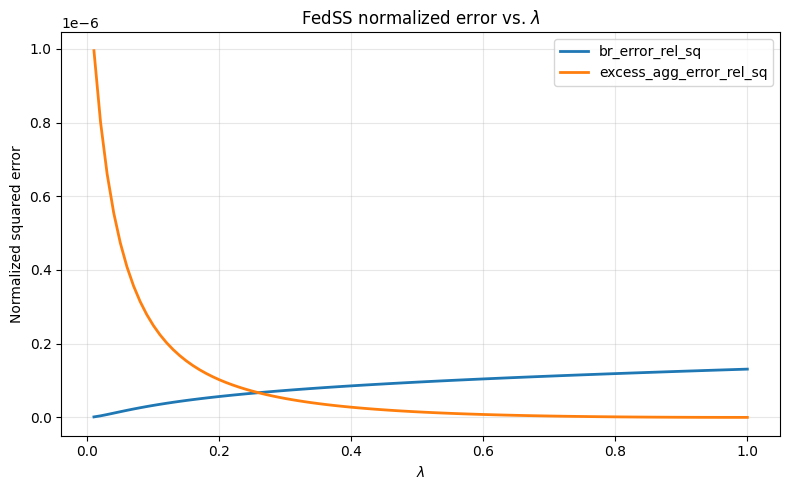

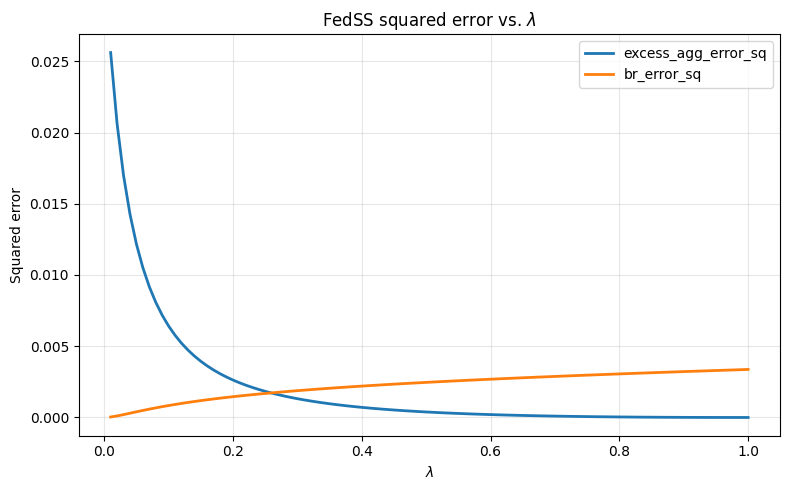

In [35]:
# ==================== 从 CSV 读取数据并绘图 ====================
import csv
from pathlib import Path
import matplotlib.pyplot as plt

# 直接读取当前 fmnist 目录下的 CSV，不使用前面代码块中的内存变量。
csv_path = Path(r"D:/vscode/CODES/paper_experiment_record/close-optimal-result/aggregation_broadcast_error/fmnist/fedss_lambda_tradeoff.csv")
if not csv_path.exists():
    raise FileNotFoundError(f'没有找到 CSV 文件：{csv_path}')

with csv_path.open('r', encoding='utf-8-sig', newline='') as csv_file:
    rows = list(csv.DictReader(csv_file))

if not rows:
    raise ValueError('CSV 文件为空')

lambda_values_from_csv = [float(row['lambda_value']) for row in rows]
csv_columns = {
    column: [float(row[column]) for row in rows]
    for column in (
        'agg_error_rel_sq',
        'br_error_rel_sq',
        'excess_agg_error_rel_sq',
        'excess_agg_error_sq',
        'br_error_sq',
    )
}

# 第一张图：归一化误差。
fig1, ax1 = plt.subplots(figsize=(8, 5))
'''
ax1.plot(
    lambda_values_from_csv,
    csv_columns['agg_error_rel_sq'],
    label='agg_error_rel_sq',
    linewidth=2,
)
'''
ax1.plot(
    lambda_values_from_csv,
    csv_columns['br_error_rel_sq'],
    label='br_error_rel_sq',
    linewidth=2,
)
ax1.plot(
    lambda_values_from_csv,
    csv_columns['excess_agg_error_rel_sq'],
    label='excess_agg_error_rel_sq',
    linewidth=2,
)
ax1.set_xlabel(r'$\lambda$')
ax1.set_ylabel('Normalized squared error')
ax1.set_title('FedSS normalized error vs. $\lambda$')
ax1.grid(True, alpha=0.3)
ax1.legend()
fig1.tight_layout()
plt.show()

# 第二张图：原始平方误差。
fig2, ax2 = plt.subplots(figsize=(8, 5))
ax2.plot(
    lambda_values_from_csv,
    csv_columns['excess_agg_error_sq'],
    label='excess_agg_error_sq',
    linewidth=2,
)
ax2.plot(
    lambda_values_from_csv,
    csv_columns['br_error_sq'],
    label='br_error_sq',
    linewidth=2,
)
ax2.set_xlabel(r'$\lambda$')
ax2.set_ylabel('Squared error')
ax2.set_title('FedSS squared error vs. $\lambda$')
ax2.grid(True, alpha=0.3)
ax2.legend()
fig2.tight_layout()
plt.show()